Epoch 1/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 469us/step - loss: 0.9325
Epoch 2/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 0s 335us/step - loss: 0.8294
Epoch 3/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 0s 332us/step - loss: 0.8107
Epoch 4/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 0s 333us/step - loss: 0.8023
Epoch 5/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 0s 342us/step - loss: 0.7969
Epoch 6/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 0s 336us/step - loss: 0.7934
Epoch 7/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 0s 334us/step - loss: 0.7901
Epoch 8/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 0s 336us/step - loss: 0.7878
Epoch 9/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 0s 334us/step - loss: 0.7859
Epoch 10/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 0s 333us/step - loss: 0.7845
7108/7108 ━━━━━━━━━━━━━━━━━━━━ 1s 158us/step
1781/1781 ━━━━━━━━━━━━━━━━━━━━ 0s 155us/step
Threshold: 1.6472542840085787


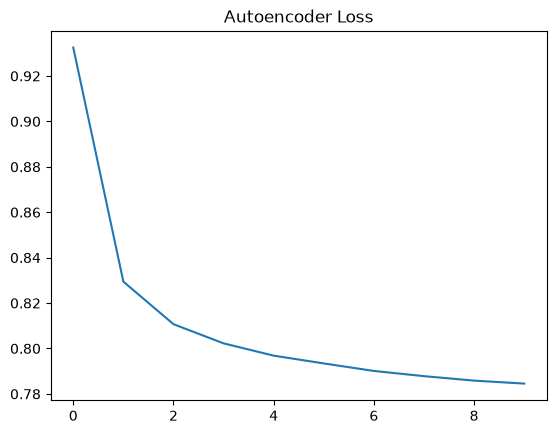

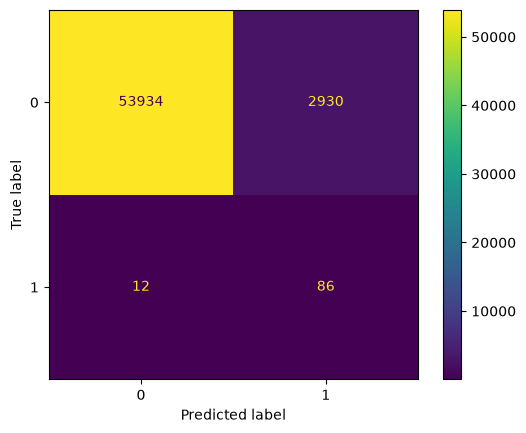

In [4]:

import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Load dataset
data = pd.read_csv('AutoEncoder/CreditCard/creditcard.csv')

X = data.drop('Class', axis=1)
y = data['Class']

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Preprocess data
X_train = X_train[y_train == 0]

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Build Autoencoder
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(X_train.shape[1], activation='sigmoid')
])

# 5. Compile model
model.compile(optimizer='adam', loss='mse')

# 6. Train model
history = model.fit(
    X_train, X_train,
    epochs=10,
    batch_size=256
)

# 7. Calculate error and detect fraud
train_pred = model.predict(X_train)
train_error = np.mean((X_train - train_pred)**2, axis=1)

threshold = np.percentile(train_error, 95)

test_pred = model.predict(X_test)
test_error = np.mean((X_test - test_pred)**2, axis=1)

y_pred = (test_error > threshold).astype(int)

# 8. Evaluate and plot
print("Threshold:", threshold)

plt.plot(history.history['loss'])
plt.title('Autoencoder Loss')
plt.show()
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

